<a href="https://colab.research.google.com/github/FaizaRahmanSanjana/Computer-Vision-And-Pattern-Recognition/blob/main/CNN_23_53877_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub torchinfo

In [2]:
import os, random, time, copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

import kagglehub
from torchinfo import summary
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------- Reproducibility ----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device: {device}")
if device.type == "cpu":
    print("WARNING: No GPU detected. Enable one via Runtime -> Change runtime type.")

PyTorch 2.14.1+cu130 | Device: cuda


In [3]:
# ---------------- Download dataset ----------------
dataset_path = kagglehub.dataset_download("mahmoudreda55/satellite-image-classification")
print("Downloaded to:", dataset_path)

CLASSES = ["cloudy", "desert", "green_area", "water"]

def find_data_root(base, class_names):
    """Walk the download folder and return the directory that directly contains all class folders."""
    for dirpath, dirnames, _ in os.walk(base):
        if set(class_names).issubset(set(dirnames)):
            return dirpath
    raise FileNotFoundError(f"Could not find folders {class_names} under {base}")

DATA_ROOT = find_data_root(dataset_path, CLASSES)
print("Data root:", DATA_ROOT)

100%|██████████| 21.8M/21.8M [00:00<00:00, 76.7MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/mahmoudreda55/satellite-image-classification/versions/1
Data root: /root/.cache/kagglehub/datasets/mahmoudreda55/satellite-image-classification/versions/1/data


Images per class:
  cloudy      :  1500  (26.6%)
  desert      :  1131  (20.1%)
  green_area  :  1500  (26.6%)
  water       :  1500  (26.6%)
  TOTAL       :  5631


/tmp/ipykernel_490/1200634813.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")


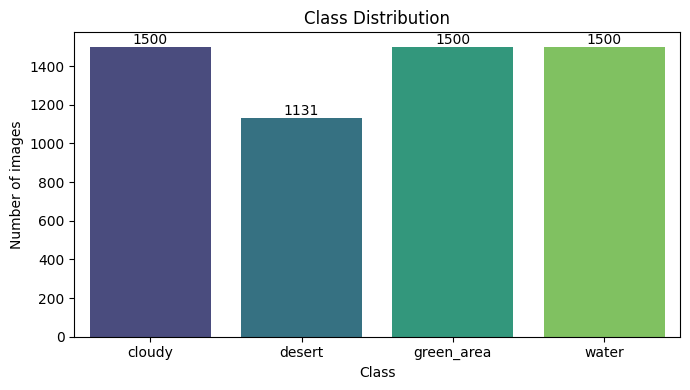

In [4]:
# ---------------- Class counts ----------------
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
class_counts = {
    c: sum(1 for f in Path(DATA_ROOT, c).rglob("*") if f.suffix.lower() in IMG_EXT)
    for c in CLASSES
}
total_images = sum(class_counts.values())

print("Images per class:")
for c, n in class_counts.items():
    print(f"  {c:<12}: {n:>5}  ({100*n/total_images:.1f}%)")
print(f"  {'TOTAL':<12}: {total_images:>5}")

# ---------------- Bar chart ----------------
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
plt.title("Class Distribution")
plt.xlabel("Class"); plt.ylabel("Number of images")
plt.tight_layout(); plt.show()

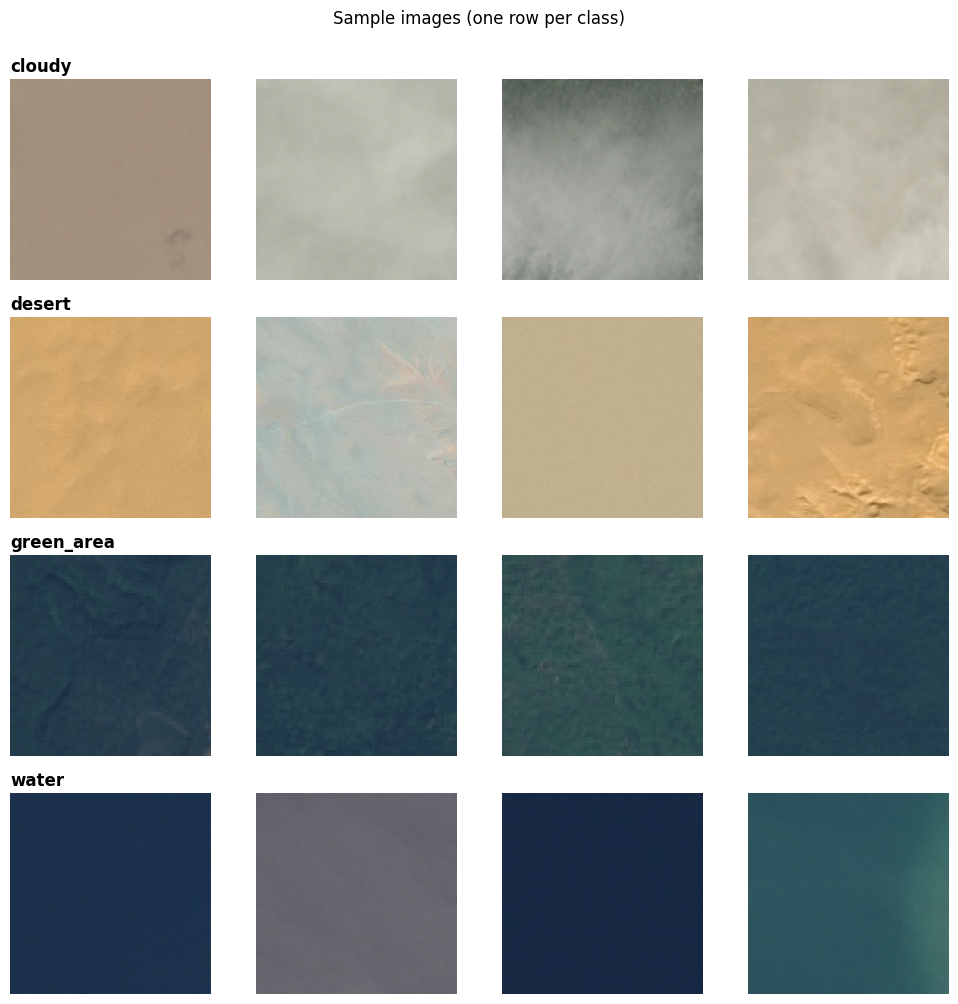

In [5]:
# ---------------- Sample grid: 4 random images per class ----------------
from PIL import Image

rng = random.Random(SEED)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for r, c in enumerate(CLASSES):
    files = [f for f in Path(DATA_ROOT, c).rglob("*") if f.suffix.lower() in IMG_EXT]
    for k, f in enumerate(rng.sample(files, 4)):
        axes[r, k].imshow(Image.open(f).convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Sample images (one row per class)", y=1.0)
plt.tight_layout(); plt.show()

In [6]:
IMG_SIZE = 128
BATCH_SIZE = 32
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(90),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Same files, two different transform pipelines
full_train_view = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
full_eval_view  = datasets.ImageFolder(DATA_ROOT, transform=eval_tf)
assert full_train_view.classes == CLASSES, f"Unexpected classes: {full_train_view.classes}"

# ---------------- 70/15/15 split on indices (seeded) ----------------
n_total = len(full_train_view)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
n_test  = n_total - n_train - n_val

g = torch.Generator().manual_seed(SEED)
train_idx, val_idx, test_idx = [s.indices for s in random_split(range(n_total), [n_train, n_val, n_test], generator=g)]

train_ds = Subset(full_train_view, train_idx)   # augmented
val_ds   = Subset(full_eval_view,  val_idx)     # clean
test_ds  = Subset(full_eval_view,  test_idx)    # clean

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Total: {n_total} | Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

def denormalize(t):
    """Undo normalisation for display: (C,H,W) tensor -> (H,W,C) numpy in [0,1]."""
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (t.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

Total: 5631 | Train: 3941 | Val: 844 | Test: 846
Batches -> train: 124, val: 27, test: 27


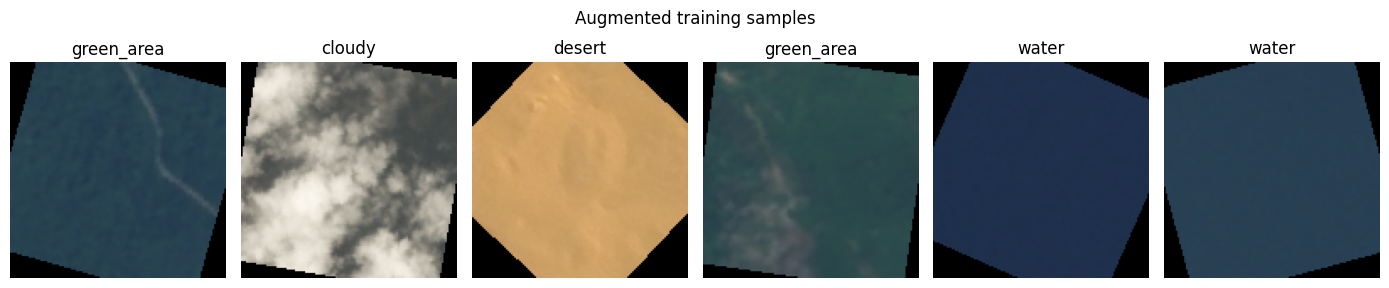

In [7]:
# Quick look at augmented training samples
imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for i, ax in enumerate(axes):
    ax.imshow(denormalize(imgs[i])); ax.set_title(CLASSES[labels[i]]); ax.axis("off")
plt.suptitle("Augmented training samples"); plt.tight_layout(); plt.show()

In [8]:
class ConvBlock(nn.Module):
    """Conv(3x3) -> BatchNorm -> ReLU -> MaxPool(2)."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
    def forward(self, x):
        return self.block(x)


class SatelliteCNN(nn.Module):
    def __init__(self, num_classes=4, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),     # 128 -> 64
            ConvBlock(32, 64),    # 64  -> 32
            ConvBlock(64, 128),   # 32  -> 16
            ConvBlock(128, 256),  # 16  -> 8
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))   # 8x8 -> 1x1
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x).flatten(1)
        x = self.dropout(x)
        return self.classifier(x)


model = SatelliteCNN(num_classes=len(CLASSES)).to(device)
summary(model, input_size=(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE),
        col_names=("input_size", "output_size", "num_params"), depth=3)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
SatelliteCNN                             [32, 3, 128, 128]         [32, 4]                   --
├─Sequential: 1-1                        [32, 3, 128, 128]         [32, 256, 8, 8]           --
│    └─ConvBlock: 2-1                    [32, 3, 128, 128]         [32, 32, 64, 64]          --
│    │    └─Sequential: 3-1              [32, 3, 128, 128]         [32, 32, 64, 64]          928
│    └─ConvBlock: 2-2                    [32, 32, 64, 64]          [32, 64, 32, 32]          --
│    │    └─Sequential: 3-2              [32, 32, 64, 64]          [32, 64, 32, 32]          18,560
│    └─ConvBlock: 2-3                    [32, 64, 32, 32]          [32, 128, 16, 16]         --
│    │    └─Sequential: 3-3              [32, 64, 32, 32]          [32, 128, 16, 16]         73,984
│    └─ConvBlock: 2-4                    [32, 128, 16, 16]         [32, 256, 8, 8]           --
│    │    └─Sequential: 3-

In [9]:
EPOCHS = 20
LR = 1e-3
MODEL_PATH = "best_cnn_satellite.pth"

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

def run_epoch(loader, train=True):
    """One pass over a loader. Returns (avg_loss, accuracy)."""
    model.train() if train else model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return running_loss / total, correct / total

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_epoch = 0.0, 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)

    flag = ""
    if va_acc > best_val_acc:                      # save best model by validation accuracy
        best_val_acc, best_epoch = va_acc, epoch
        torch.save(model.state_dict(), MODEL_PATH)
        flag = "  <-- best, saved"

    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f}{flag}")

print(f"\nDone in {(time.time()-start)/60:.1f} min | best val acc {best_val_acc:.4f} at epoch {best_epoch}")

Epoch 01/20 | train loss 0.4128 acc 0.8419 | val loss 0.2560 acc 0.8874  <-- best, saved
Epoch 02/20 | train loss 0.3305 acc 0.8635 | val loss 0.5188 acc 0.7796
Epoch 03/20 | train loss 0.3104 acc 0.8759 | val loss 0.2738 acc 0.8886  <-- best, saved
Epoch 04/20 | train loss 0.3021 acc 0.8792 | val loss 0.2568 acc 0.9111  <-- best, saved
Epoch 05/20 | train loss 0.2870 acc 0.8795 | val loss 0.2098 acc 0.9206  <-- best, saved
Epoch 06/20 | train loss 0.2621 acc 0.8947 | val loss 0.1823 acc 0.9230  <-- best, saved
Epoch 07/20 | train loss 0.2754 acc 0.8876 | val loss 0.2547 acc 0.8827
Epoch 08/20 | train loss 0.2633 acc 0.8932 | val loss 0.2643 acc 0.8910
Epoch 09/20 | train loss 0.2574 acc 0.8972 | val loss 0.2179 acc 0.9111
Epoch 10/20 | train loss 0.2382 acc 0.9018 | val loss 0.2059 acc 0.9052
Epoch 11/20 | train loss 0.2361 acc 0.9051 | val loss 0.2248 acc 0.9301  <-- best, saved
Epoch 12/20 | train loss 0.2350 acc 0.9031 | val loss 0.2392 acc 0.8886
Epoch 13/20 | train loss 0.2229 ac

In [10]:
# Fresh model + best weights
best_model = SatelliteCNN(num_classes=len(CLASSES)).to(device)
best_model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
best_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds = best_model(x.to(device)).argmax(1).cpu()
        all_preds.extend(preds.tolist()); all_labels.extend(y.tolist())

all_preds, all_labels = np.array(all_preds), np.array(all_labels)
test_acc = accuracy_score(all_labels, all_preds)

print(f"TEST ACCURACY: {test_acc*100:.2f}%  ({(all_preds==all_labels).sum()}/{len(all_labels)} correct)\n")
print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=4))

TEST ACCURACY: 94.44%  (799/846 correct)

              precision    recall  f1-score   support

      cloudy     0.9265    0.9870    0.9558       230
      desert     0.9873    0.9017    0.9426       173
  green_area     0.8956    0.9955    0.9429       224
       water     0.9948    0.8813    0.9346       219

    accuracy                         0.9444       846
   macro avg     0.9511    0.9414    0.9440       846
weighted avg     0.9485    0.9444    0.9442       846



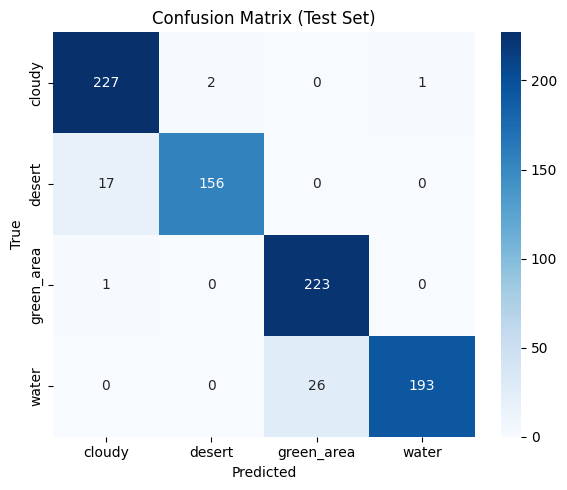

In [11]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix (Test Set)")
plt.tight_layout(); plt.show()

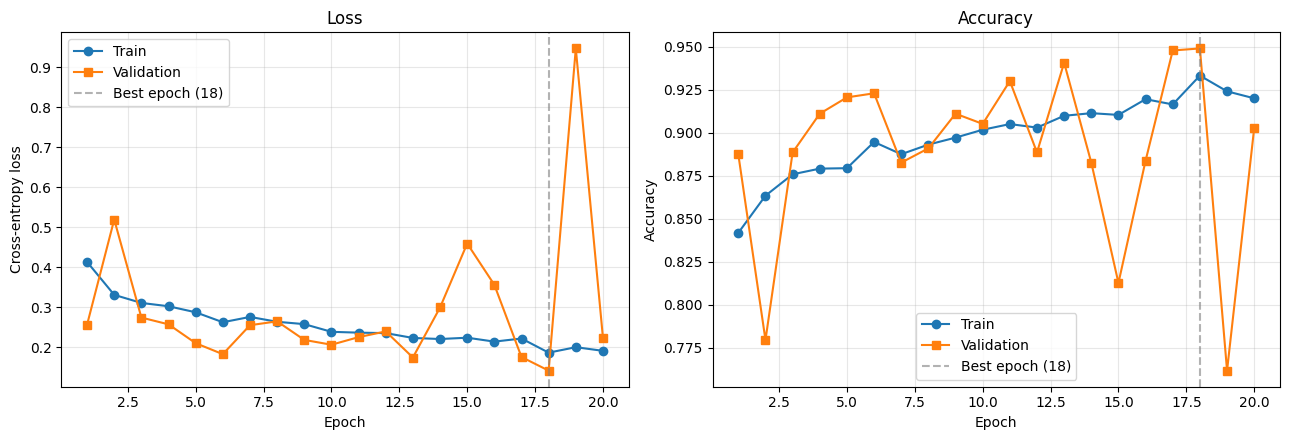

In [12]:
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, history["train_loss"], "o-", label="Train")
axes[0].plot(epochs_range, history["val_loss"],   "s-", label="Validation")
axes[0].axvline(best_epoch, color="gray", ls="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["train_acc"], "o-", label="Train")
axes[1].plot(epochs_range, history["val_acc"],   "s-", label="Validation")
axes[1].axvline(best_epoch, color="gray", ls="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

In [13]:
# ---------------- 1) Over/underfitting diagnostics ----------------
final_tr, final_va = history["train_acc"][-1], history["val_acc"][-1]
gap = final_tr - final_va
print(f"Best epoch: {best_epoch} | best val acc: {best_val_acc:.4f}")
print(f"Final train acc: {final_tr:.4f} | final val acc: {final_va:.4f} | gap (train - val): {gap*100:+.2f} pts")
print(f"Final train loss: {history['train_loss'][-1]:.4f} | final val loss: {history['val_loss'][-1]:.4f}")

if final_tr < 0.80 and final_va < 0.80:
    verdict = "UNDERFITTING: both accuracies are low -> increase capacity / train longer."
elif gap > 0.05 or history["val_loss"][-1] > min(history["val_loss"]) * 1.15:
    verdict = "SIGN OF OVERFITTING: train > val and/or val loss rising -> more regularisation/augmentation."
else:
    verdict = "GOOD FIT: train and validation behave similarly and plateau at a high level."
print("Verdict:", verdict)

Best epoch: 18 | best val acc: 0.9491
Final train acc: 0.9201 | final val acc: 0.9028 | gap (train - val): +1.72 pts
Final train loss: 0.1906 | final val loss: 0.2229
Verdict: SIGN OF OVERFITTING: train > val and/or val loss rising -> more regularisation/augmentation.


In [14]:
# ---------------- 2) Per-class accuracy & top confusions ----------------
per_class_acc = cm.diagonal() / cm.sum(axis=1)
print("\nPer-class test accuracy:")
for c, a in zip(CLASSES, per_class_acc):
    print(f"  {c:<12}: {a*100:.2f}%")

errors = [(CLASSES[t], CLASSES[p], int(cm[t, p]))
          for t in range(len(CLASSES)) for p in range(len(CLASSES)) if t != p and cm[t, p] > 0]
errors.sort(key=lambda e: e[2], reverse=True)
print("\nMost frequent confusions (true -> predicted):")
for t, p, n in errors[:5]:
    print(f"  {t} -> {p}: {n} images")
if not errors:
    print("  None - perfect classification on the test set.")


Per-class test accuracy:
  cloudy      : 98.70%
  desert      : 90.17%
  green_area  : 99.55%
  water       : 88.13%

Most frequent confusions (true -> predicted):
  water -> green_area: 26 images
  desert -> cloudy: 17 images
  cloudy -> desert: 2 images
  cloudy -> water: 1 images
  green_area -> cloudy: 1 images



Misclassified: 47 of 846 test images


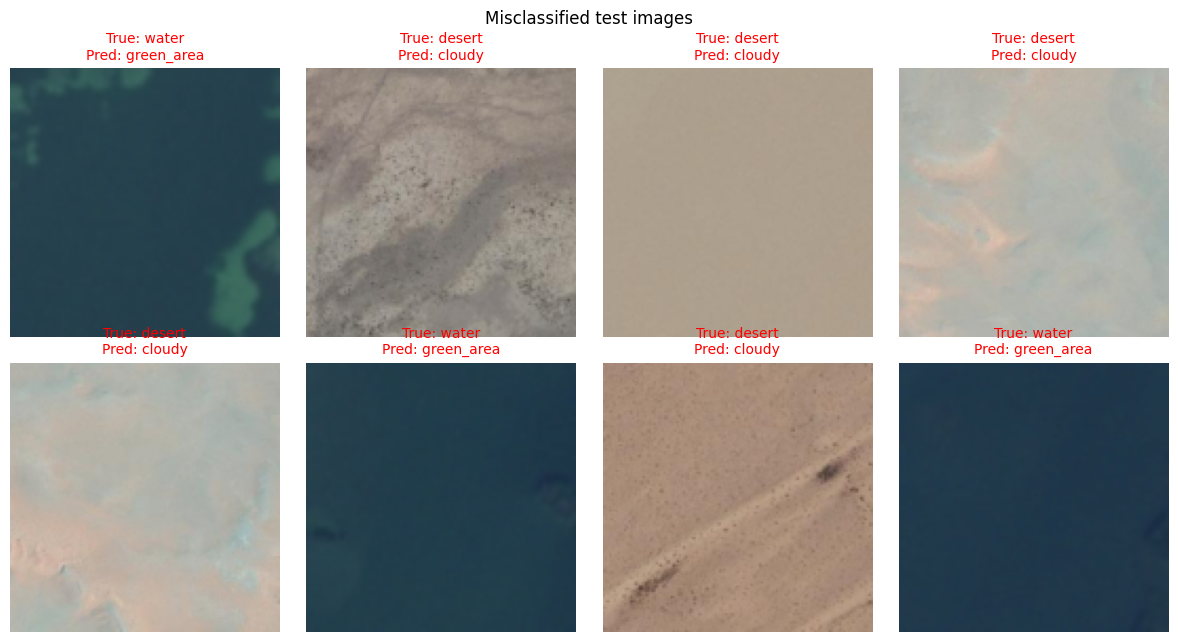

In [15]:
# ---------------- 3) Misclassified examples ----------------
wrong = np.where(all_preds != all_labels)[0]
print(f"\nMisclassified: {len(wrong)} of {len(all_labels)} test images")

if len(wrong) > 0:
    show = wrong[:8]
    fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
    for ax, idx in zip(axes.ravel(), show):
        img, _ = test_ds[idx]       # test_loader is unshuffled -> same order as test_ds
        ax.imshow(denormalize(img))
        ax.set_title(f"True: {CLASSES[all_labels[idx]]}\nPred: {CLASSES[all_preds[idx]]}", fontsize=10, color="red")
        ax.axis("off")
    for ax in axes.ravel()[len(show):]:
        ax.axis("off")
    plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.show()

In [16]:
# ---------------- 4) Verify saved-weights size < 20 MB ----------------
size_bytes = os.path.getsize(MODEL_PATH)
size_mb = size_bytes / (1024 ** 2)
n_params = sum(p.numel() for p in model.parameters())
print(f"File: {MODEL_PATH} | size: {size_bytes:,} bytes = {size_mb:.2f} MB | parameters: {n_params:,}")
print("Constraint (< 20 MB):", "PASSED" if size_mb < 20 else "FAILED")
assert size_mb < 20, "Model file exceeds the 20 MB limit!"

File: best_cnn_satellite.pth | size: 1,573,685 bytes = 1.50 MB | parameters: 389,924
Constraint (< 20 MB): PASSED
